# Exploring the Dash *et al* dataset

This data was generated in [Quantifiable predictive features define epitope specific T cell  receptor repertoires](https://doi.org/10.1038/nature22383) and further analysed in [Measures of epitope binding degeneracy from T cell receptor repertoires](https://www.pnas.org/doi/abs/10.1073/pnas.2213264120). In this notebook we explore the dataset and re-create some of the analysis done in other works.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pyxdameraulevenshtein import damerau_levenshtein_distance
from sklearn.cluster import AgglomerativeClustering

In [2]:
dash = pd.read_csv('../data/external/dash_human.csv')

In [3]:
dash = dash.dropna()

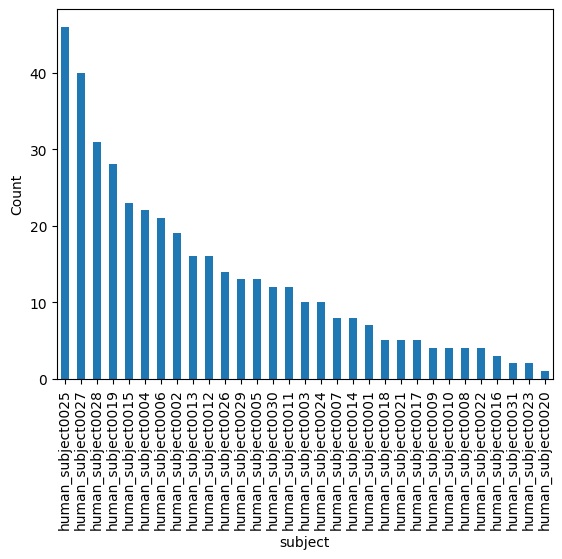

In [4]:
dash['subject'].value_counts().plot.bar()

plt.ylabel('Count')

plt.show()

In [5]:
dash.value_counts('epitope')

epitope
M1      249
BMLF     92
pp65     67
Name: count, dtype: int64

## BMLF Epitope Analysis

In [6]:
dash_bmlf = dash.query("epitope == 'BMLF'")

In [7]:
num_tcrs = len(dash_bmlf)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_a_aa'], dash.iloc[j]['cdr3_a_aa']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_b_aa'], dash.iloc[j]['cdr3_b_aa']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [8]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [9]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [10]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [11]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
n_colours = len(palette)

cluster_to_colour = {cluster: palette[i % n_colours] for i, cluster in enumerate(unique_clusters)}
colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

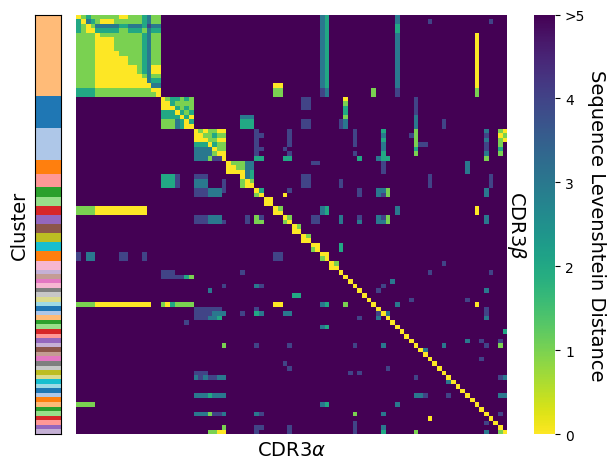

In [12]:
CLIP_DISTANCE = 5

fig, (ax1, ax2) = plt.subplots(1, 2, gridspec_kw={'width_ratios': [1, 20]})

ax1.imshow(colours, aspect='auto')

ax1.set_ylabel('Cluster', fontsize=14)
ax1.set_xticks([])
ax1.set_xticklabels('')
ax1.set_yticks([])
ax1.set_yticklabels('')

sns.heatmap(
    np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE), cmap='viridis_r', ax=ax2
)

ax2.set_xlabel(r'CDR3$\alpha$', fontsize=14)
ax2.set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
ax2.yaxis.set_label_position('right')

ax2.set_xticks([])
ax2.set_xticklabels('')
ax2.set_yticks([])
ax2.set_yticklabels('')

cbar = ax2.collections[0].colorbar
cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
cbar.set_ticks(cbar.get_ticks())
cbar.set_ticklabels([f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()])

fig.set_layout_engine('tight')

plt.show()